# Phase C: Vom Tag zur Sequenz

Schritte 9 bis 11 aus `LERNPLAN.md`. Hier geht es noch nicht um die Befunde, sondern darum, die Daten als ganze Tage aufzubereiten und den nächsten Tag vorherzusagen. Das ist die Vorbereitung für das LSTM.

## Setup

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
METER_DIR = ROOT / "data" / "processed" / "real_meters"
BILDER = ROOT / "docs" / "assets" / "lernpfad"

sys.path.insert(0, str(ROOT))

## Schritt 9: Ein Tag als Zeile

Bisher hatte jede Station ein paar Kennzahlen. Ein Median macht aber einen ganzen Winter zu einer Zahl, und wann am Tag etwas passiert, geht verloren. Jetzt bekommt jeder Tag eine Zeile mit 24 Stunden. Erst für unsere Station 68956351:

In [3]:
df = pd.read_csv(METER_DIR / "68956351.csv", parse_dates=["Timestamp"])
df["tag"] = df["Timestamp"].dt.date
df["stunde"] = df["Timestamp"].dt.hour

`pivot` dreht die Tabelle: jeder Tag eine Zeile, jede Stunde eine Spalte.

In [4]:
tage_rl = df.pivot(index="tag", columns="stunde", values="Return temperature (°C)")
tage_rl.head()

stunde,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
tag,,,,,,,,,,,,,,,,,,,,,
2021-11-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.5
2021-11-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.1
2021-11-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,75.7
2021-11-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.2
2021-11-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,73.0


In [5]:
tage_rl.shape

(1349, 24)

1349 Tage, `head()` zeigt nur die ersten 5. Das LSTM braucht vollständige Tage, also alle Tage raus, an denen auch nur eine Stunde fehlt:

In [6]:
volle_tage = tage_rl.dropna()

In [7]:
volle_tage.shape

(960, 24)

960 vollständige Tage, also 71 %. Die anderen fallen vor allem wegen der Zeit mit Tageswerten raus (Phase A).

In [10]:
volle_tage.describe()

stunde,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
count,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,...,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000,960.000000
mean,62.547604,61.888333,61.119062,60.751979,60.238646,59.803021,59.121667,63.348750,66.105313,65.325625,...,66.681562,66.348021,65.365104,65.653229,66.369687,65.920417,65.439688,63.738438,64.799583,65.043646
std,20.296481,20.987601,21.478736,21.748675,21.810599,21.919754,21.574064,17.104726,12.154383,14.804422,...,14.579483,14.959116,16.173616,16.123955,14.943211,15.119711,15.833569,17.944174,17.138945,17.410727
min,24.200000,23.700000,23.700000,23.500000,23.500000,23.500000,23.700000,23.700000,24.600000,24.100000,...,24.900000,25.000000,24.900000,24.700000,24.900000,24.700000,24.400000,24.100000,23.900000,24.200000
25%,43.250000,39.400000,36.675000,34.400000,32.600000,31.275000,30.000000,60.475000,57.500000,56.800000,...,58.200000,56.500000,53.075000,59.400000,60.875000,58.500000,57.475000,53.875000,58.375000,55.975000
50%,73.450000,73.000000,72.850000,72.600000,72.100000,71.950000,70.700000,68.100000,69.400000,70.200000,...,72.800000,73.200000,72.600000,72.600000,71.600000,71.700000,72.000000,71.900000,72.700000,73.550000
75%,76.900000,77.000000,76.800000,76.400000,75.900000,75.800000,75.600000,75.300000,75.000000,75.800000,...,76.700000,76.800000,76.800000,76.600000,76.700000,76.300000,76.300000,76.300000,76.400000,76.800000
max,84.200000,84.800000,84.500000,84.700000,83.700000,84.800000,84.800000,85.200000,85.100000,85.100000,...,85.100000,84.500000,84.600000,83.600000,83.500000,83.800000,84.400000,83.900000,84.100000,84.600000


In [11]:
volle_tage.index = pd.to_datetime(volle_tage.index)

Vier Wintertage, zwei vor und zwei nach dem Tausch:

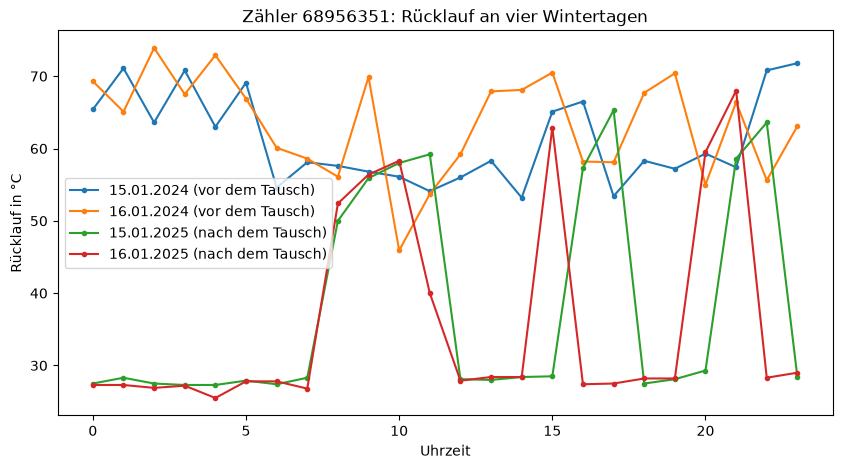

In [12]:
beispiel = volle_tage.loc[["2024-01-15", "2024-01-16", "2025-01-15", "2025-01-16"]]
ax = beispiel.T.plot(figsize=(10, 5), marker=".")
ax.set_title("Zähler 68956351: Rücklauf an vier Wintertagen")
ax.set_xlabel("Uhrzeit")
ax.set_ylabel("Rücklauf in °C")
ax.legend(["15.01.2024 (vor dem Tausch)", "16.01.2024 (vor dem Tausch)", "15.01.2025 (nach dem Tausch)", "16.01.2025 (nach dem Tausch)"])

In [16]:
ax.figure.savefig(BILDER / "09_tage_vor_nach.png", bbox_inches="tight")

Vor dem Tausch bleibt der Rücklauf den ganzen Tag hoch (55 bis 71 °C), danach springt er zwischen ca. 28 und 60 °C. Das ruhige Bild vorher ist der Fehler: Das Ventil schließt nie. Nachher öffnet die Station nur, wenn Wärme gebraucht wird, dazwischen steht das Wasser und kühlt ab (Takten). Das sieht man nur im Tagesverlauf, nicht in einer Kennzahl.

### Mehrere Kanäle

Pro Stunde soll das Modell mehrere Werte sehen: Rücklauf, Durchfluss und Vorlauf. Jede Messgröße ist ein Kanal.

In [13]:
kanaele = {
    "ruecklauf": "Return temperature (°C)",
    "durchfluss": "Volume flow (l/h)",
    "vorlauf": "Flow temperature (°C)",
}

tabellen = {}
for name, spalte in kanaele.items():
    tabellen[name] = df.pivot(index="tag", columns="stunde", values=spalte)

In [14]:
alle = pd.concat(tabellen, axis=1).dropna()
alle.shape

(960, 72)

In [15]:
X = alle.values.reshape(len(alle), 3, 24).transpose(0, 2, 1)
X.shape

(960, 24, 3)

Ein Tensor mit 960 Tagen × 24 Stunden × 3 Kanälen. Wie ein Buch: jede Seite ein Tag, jede Zeile eine Stunde, jede Spalte ein Kanal.

### Skalierung

Die Kanäle liegen in ganz verschiedenen Größenordnungen (Durchfluss bis fast 1000 l/h, Temperaturen zwischen 25 und 80 °C). In einem Netz würde sonst der Kanal mit den größten Zahlen alles bestimmen. Mittelwert und Streuung nehmen wir nur aus der Zeit vor dem Tausch, sonst steckt Wissen aus der Zukunft in der Skalierung (Leakage):

In [17]:
vor_tausch = pd.to_datetime(alle.index) < "2024-09-09"
X_vor = X[vor_tausch]

In [18]:
mittel = X_vor.mean(axis=(0, 1))
streuung = X_vor.std(axis=(0, 1))
mittel, streuung

(array([ 74.32725431, 672.10758612,  76.57160588]),
 array([  5.64633127, 139.19167023,   3.20391482]))

In [20]:
X_skaliert = (X - mittel) / streuung

Vor dem Tausch hat jetzt jeder Kanal Mittelwert 0 und Streuung 1. Und nach dem Tausch?

In [21]:
X_skaliert[~vor_tausch].mean(axis=(0, 1))

array([-5.84986747, -4.30116717, -5.16596032])

Alle drei Kanäle liegen im Mittel 4 bis 6 Streuungen unter dem, was vorher normal war. Das ist keine größere Streuung, sondern eine Verschiebung: Die Station verhält sich ganz anders als vorher. So soll später der Wächter (Phase F) Veränderungen finden.

### Alle begangenen Stationen

Jetzt dasselbe für alle 56 begangenen Stationen, jeweils ab November 2022 und vor dem Stichtag. Als vierter Kanal kommt die Außentemperatur dazu, ohne Wetter kann man den nächsten Tag nicht vorhersagen. Erst das Ende für jede Station (Begehung, spätestens 01.09.2024):

In [22]:
labels = pd.read_csv(ROOT / "data" / "processed" / "modell_labels.csv", parse_dates=["erste_begehung"])
labels["ende"] = labels["erste_begehung"].fillna(pd.Timestamp("2024-09-01")).clip(upper=pd.Timestamp("2024-09-01"))

Das Wetter einmal als Tag × Stunde:

In [23]:
from src.weather import load_outdoor_temperature

wetter = load_outdoor_temperature("2022-11-01", "2024-09-01")
wetter["tag"] = wetter["timestamp"].dt.date
wetter["stunde"] = wetter["timestamp"].dt.hour
aussen = wetter.pivot(index="tag", columns="stunde", values="t_out")

Die Schleife macht für jede Station dasselbe wie oben für eine. In `info_liste` merken wir uns, zu welcher Station und welchem Tag jede Zeile gehört, im Tensor stehen ja nur Zahlen:

In [24]:
X_liste = []
info_liste = []

for z, ende in zip(labels["zaehler"], labels["ende"]):
    d = pd.read_csv(METER_DIR / f"{z}.csv", parse_dates=["Timestamp"])
    d = d[(d["Timestamp"] >= "2022-11-01") & (d["Timestamp"] < ende)]
    d["tag"] = d["Timestamp"].dt.date
    d["stunde"] = d["Timestamp"].dt.hour

    tabellen = {}
    for name, spalte in kanaele.items():
        tabellen[name] = d.pivot(index="tag", columns="stunde", values=spalte)
    tabellen["aussen"] = aussen

    alle = pd.concat(tabellen, axis=1).dropna()
    X_liste.append(alle.values.reshape(len(alle), 4, 24).transpose(0, 2, 1))
    info_liste.append(pd.DataFrame({"zaehler": z, "tag": alle.index}))

In [26]:
import numpy as np

X_alle = np.concatenate(X_liste)
info = pd.concat(info_liste, ignore_index=True)
X_alle.shape


(24684, 24, 4)

24.684 Tage × 24 Stunden × 4 Kanäle, das sind die rund 24.000 Messtage aus Schritt 1. Wie viele Stationen sind das?

In [ ]:
info["zaehler"].nunique()

Nur 54, nicht 56. Bei 80912191 und 81019433 gibt es vor dem Stichtag keinen einzigen vollständigen Tag.

Speichern, damit Phase D den Tensor laden kann:

In [47]:
LERNPFAD = ROOT / "data" / "processed" / "lernpfad"
LERNPFAD.mkdir(parents=True, exist_ok=True)

np.save(LERNPFAD / "X_tage.npy", X_alle)
info.to_csv(LERNPFAD / "info_tage.csv", index=False)

## Schritt 10: Den nächsten Tag vorhersagen

Das LSTM soll später aus den letzten Tagen den nächsten vorhersagen. Vorher brauchen wir eine Messlatte ohne Lernen: "wie gestern" und das Mittel der letzten 7 Tage. Gemessen wird, wie viel Grad die Vorhersage beim Rücklauf im Mittel danebenliegt (mittlerer absoluter Fehler).

In [27]:
rl = pd.DataFrame(X_alle[:, :, 0])
rl["zaehler"] = info["zaehler"]
rl["tag"] = pd.to_datetime(info["tag"])

In [28]:
fehler_gestern = []
fehler_woche = []

for z, gruppe in rl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns="zaehler").asfreq("D")
    gestern = g.shift(1)
    woche = g.rolling(7).mean().shift(1)

    da = woche.notna().all(axis=1) & g.notna().all(axis=1)
    fehler_gestern.append((g - gestern)[da].abs())
    fehler_woche.append((g - woche)[da].abs())

`asfreq("D")` fügt fehlende Tage als leere Zeilen ein, sonst wäre "gestern" einfach die vorherige Zeile. `shift(1)` sorgt dafür, dass der vorhergesagte Tag selbst nicht im Mittel steckt.

In [29]:
print("wie gestern:", pd.concat(fehler_gestern).values.mean())
print("Mittel 7 Tage:", pd.concat(fehler_woche).values.mean())

wie gestern: 5.72564842209073
Mittel 7 Tage: 5.226790238853849


Das Mittel der 7 Tage ist ein halbes Grad besser. Es glättet den Zufall des Taktens weg.

## Schritt 11: Aufteilung nach der Zeit

Ab jetzt wird gelernt, also brauchen wir Training, Validierung und Test. Zufällig nach Tagen aufteilen geht nicht: Nachbartage gleichen sich fast aufs Haar, ein Testtag hätte seinen Vortag im Training. Deshalb:

- Training: November 2022 bis Mai 2024
- Validierung: 10 % ganze Kalenderwochen daraus
- Test: Juni bis August 2024, vor allen Begehungen

In [33]:
info["tag"] = pd.to_datetime(info["tag"])
info["woche"] = info["tag"].dt.to_period("W").astype(str)

In [34]:
test = info["tag"] >= "2024-06-01"

wochen = info.loc[~test, "woche"].unique()
np.random.seed(0)
val_wochen = np.random.choice(wochen, size=int(0.1 * len(wochen)), replace=False)

val = info["woche"].isin(val_wochen) & ~test
train = ~test & ~val

In [35]:
train.sum(), val.sum(), test.sum()

(np.int64(18689), np.int64(1511), np.int64(4484))

Ca. 76 % Training, 6 % Validierung, 18 % Test.

### Ridge-Regression

Das erste gelernte Modell. Es bekommt einen ganzen Tag (24 × 4 Werte) und die Außentemperatur von morgen (die gibt es im Einsatz als Wettervorhersage) und sagt den Rücklauf von morgen vorher. Dafür brauchen wir Paare aus heute und morgen derselben Station:

In [37]:
naechster = info.groupby("zaehler")["tag"].shift(-1)
paar = (naechster - info["tag"]) == pd.Timedelta(days=1)
heute = np.where(paar)[0]
morgen = heute + 1

In [38]:
eingabe = np.concatenate([X_alle[heute].reshape(len(heute), -1), X_alle[morgen, :, 3]], axis=1)
ziel = X_alle[morgen, :, 0]
eingabe.shape, ziel.shape

((24236, 120), (24236, 24))

120 Zahlen rein, 24 raus. Der `StandardScaler` steckt in der Pipeline und lernt deshalb nur aus dem Training:

In [40]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ist_train = train.values[morgen]
ist_val = val.values[morgen]
ist_test = test.values[morgen]

ridge = make_pipeline(StandardScaler(), Ridge(alpha=10))
ridge.fit(eingabe[ist_train], ziel[ist_train])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,120
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](120,)","[ 43.45,123.85, 61.9 ,..., 10.02, 9.23, 8.66]"


In [41]:
for name, teil in [("Validierung", ist_val), ("Test", ist_test)]:
    f_ridge = np.abs(ridge.predict(eingabe[teil]) - ziel[teil]).mean()
    f_gestern = np.abs(X_alle[heute][teil][:, :, 0] - ziel[teil]).mean()
    print(name, "Ridge:", round(f_ridge, 2), "  wie gestern:", round(f_gestern, 2))

Validierung Ridge: 5.31   wie gestern: 5.85
Test Ridge: 4.84   wie gestern: 4.71


Auf der Validierung ist Ridge besser als "wie gestern", im Test (Sommer 2024) schlechter. Aus welchen Monaten kommen die Trainingstage?

In [42]:
monat = info["tag"].dt.month.values[morgen]
pd.Series(monat[ist_train]).value_counts().sort_index()

1     1834
2     2035
3     2261
4     2212
5     2167
6      688
7      695
8      450
9      830
10    1256
11    1631
12    2349
Name: count, dtype: int64

Nur 1.833 Trainingstage aus Juni bis August, aber 6.218 aus Dezember bis Februar. Ridge hat vor allem den Heizbetrieb gelernt, im Sommer sieht es anders aus. Der Test unterscheidet sich vom Training (Verteilungsverschiebung).

### Fensterlänge

Statt nur 7 Tage probieren wir verschiedene Fenster. Ausgesucht wird auf der Validierung, nicht im Test, sonst wäre es wieder eine Auswahl nach dem Ergebnis (Phase B, Schritt 8). Fenster 1 ist "wie gestern".

In [43]:
fenster = [1, 3, 7, 14, 30]
vorhersagen = {}
for f in fenster:
    vorhersagen[f] = np.full((len(info), 24), np.nan)

for z, gruppe in rl.groupby("zaehler"):
    g = gruppe.set_index("tag").drop(columns="zaehler").asfreq("D")
    for f in fenster:
        w = g.rolling(f).mean().shift(1)
        vorhersagen[f][gruppe.index] = w.loc[gruppe["tag"]].values

In [44]:
alle_da = np.ones(len(info), dtype=bool)
for f in fenster:
    alle_da = alle_da & ~np.isnan(vorhersagen[f]).any(axis=1)

wahr = X_alle[:, :, 0]
teil = alle_da & val.values
for f in fenster:
    print(f, "Tage:", np.abs(vorhersagen[f][teil] - wahr[teil]).mean().round(2))

1 Tage: 6.05
3 Tage: 5.38
7 Tage: 5.32
14 Tage: 5.52
30 Tage: 6.2


U-Form: Zu kurz nimmt den Zufall von gestern mit, zu lang das Wetter von vor Wochen. Am besten sind 7 Tage. Erst jetzt einmal in den Test:

In [45]:
teil = alle_da & test.values
print("7 Tage im Test:", np.abs(vorhersagen[7][teil] - wahr[teil]).mean().round(2))
print("wie gestern im Test:", np.abs(vorhersagen[1][teil] - wahr[teil]).mean().round(2))

7 Tage im Test: 4.28
wie gestern im Test: 4.66


## Ergebnis Phase C

- Die Daten liegen als Tensor vor: 24.684 Tage × 24 Stunden × 4 Kanäle von 54 Stationen, gespeichert in `data/processed/lernpfad/`.
- Die Messlatte für das LSTM ist das 7-Tage-Mittel: 5,32 °C auf der Validierung und 4,28 °C im Test (auf den Tagen mit 30 Tagen Vorgeschichte).
- Ridge ist im Sommer schlechter als die einfachen Regeln, weil im Training kaum Sommer ist. Beim LSTM müssen wir den Sommer getrennt prüfen, zumal dort das Ventilsignal liegt.
- Skalierung und alles, was aus Daten berechnet wird, nur aus dem Training. Stellschrauben nur auf der Validierung wählen.